In [1]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

# Load dataset
from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")

display(df.head())


Saving advertising.csv to advertising (1).csv
Dataset loaded successfully!


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [2]:

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())


Dataset Shape: (200, 4)

Column Names:
['TV', 'Radio', 'Newspaper', 'Sales']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB

Missing Values:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Duplicate Rows: 0

Statistical Summary:


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


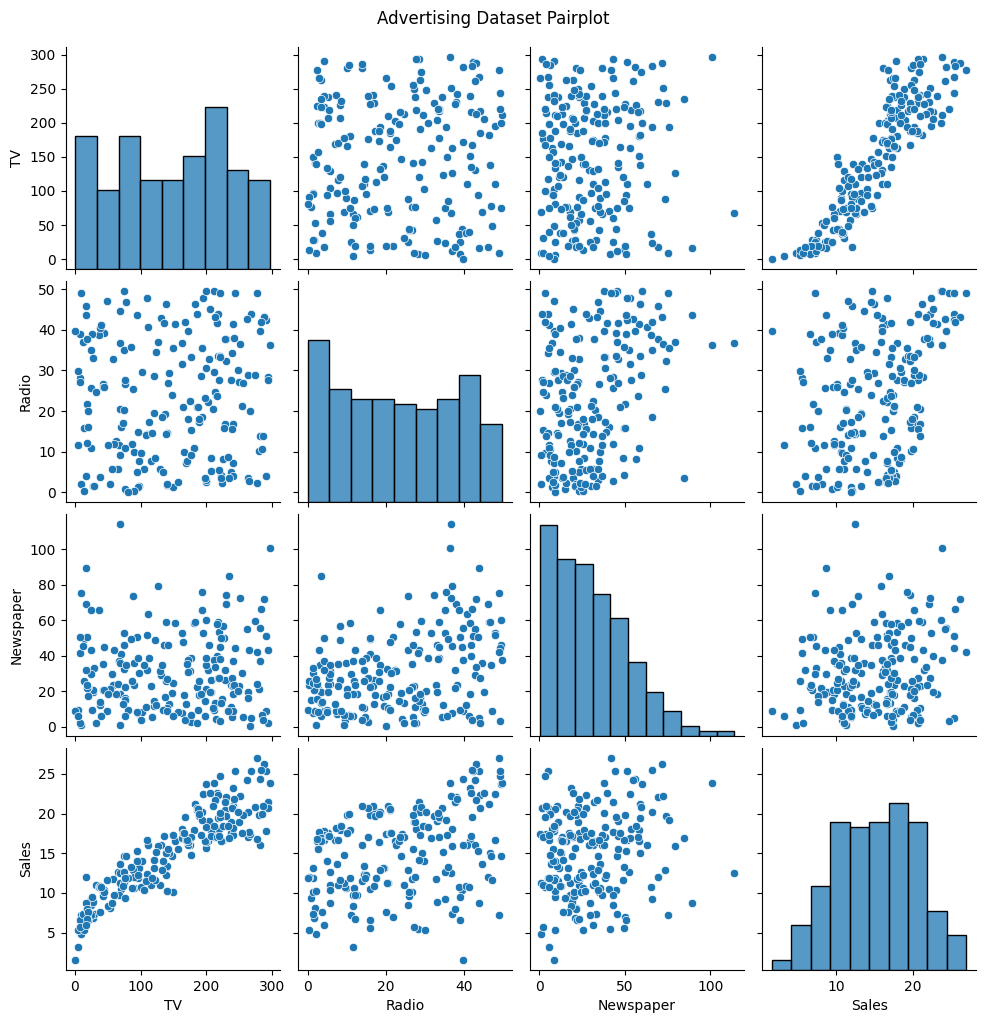

In [3]:

sns.pairplot(df)
plt.suptitle("Advertising Dataset Pairplot", y=1.02)
plt.show()


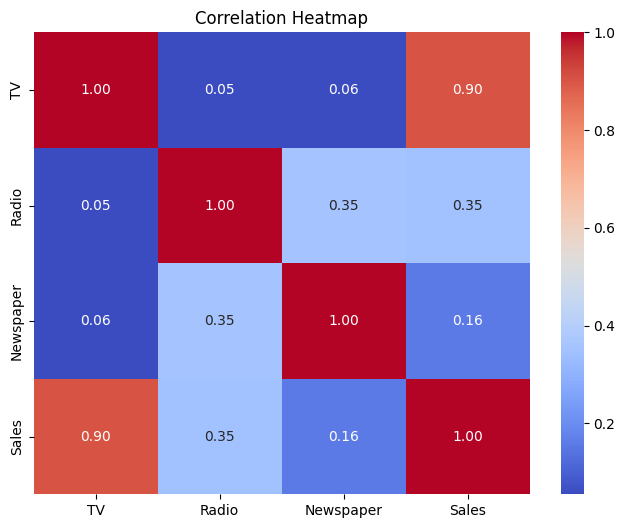

In [4]:

plt.figure(figsize=(8, 6))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()


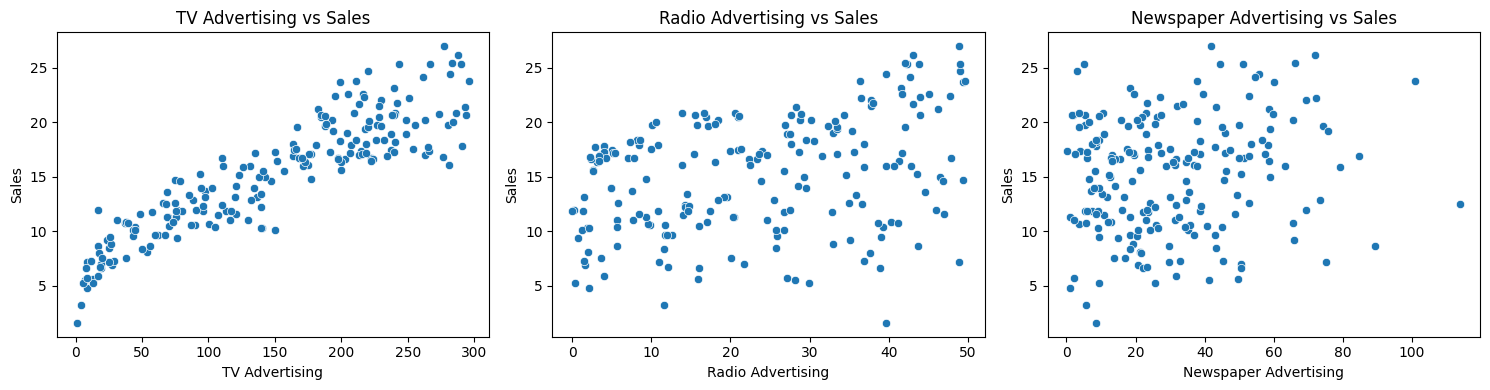

In [5]:

advertising_channels = ['TV', 'Radio', 'Newspaper']

plt.figure(figsize=(15, 4))

for i, col in enumerate(advertising_channels, 1):
    plt.subplot(1, 3, i)

    sns.scatterplot(
        data=df,
        x=col,
        y='Sales'
    )

    plt.title(f'{col} Advertising vs Sales')
    plt.xlabel(f'{col} Advertising')
    plt.ylabel('Sales')

plt.tight_layout()
plt.show()


In [6]:

# Define input features and target

X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (160, 3)
Testing Data: (40, 3)


In [7]:

# Create Linear Regression model

lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

# Predict sales
lr_predictions = lr_model.predict(X_test)

print("Linear Regression Model trained successfully!")


Linear Regression Model trained successfully!


In [8]:

# Evaluation metrics

lr_mae = mean_absolute_error(y_test, lr_predictions)

lr_rmse = np.sqrt(
    mean_squared_error(y_test, lr_predictions)
)

lr_r2 = r2_score(y_test, lr_predictions)

print("LINEAR REGRESSION PERFORMANCE")
print("-" * 40)
print("MAE :", round(lr_mae, 3))
print("RMSE:", round(lr_rmse, 3))
print("R2 Score:", round(lr_r2, 3))


LINEAR REGRESSION PERFORMANCE
----------------------------------------
MAE : 1.275
RMSE: 1.705
R2 Score: 0.906


In [9]:

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_r2 = r2_score(y_test, rf_predictions)

print("RANDOM FOREST PERFORMANCE")
print("-" * 40)
print("MAE :", round(rf_mae, 3))
print("RMSE:", round(rf_rmse, 3))
print("R2 Score:", round(rf_r2, 3))


RANDOM FOREST PERFORMANCE
----------------------------------------
MAE : 0.918
RMSE: 1.199
R2 Score: 0.953


In [10]:

model_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [lr_mae, rf_mae],
    'RMSE': [lr_rmse, rf_rmse],
    'R2 Score': [lr_r2, rf_r2]
})

display(model_comparison)


,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.274826,1.705215,0.905901
1,Random Forest,0.918000,1.198930,0.953483


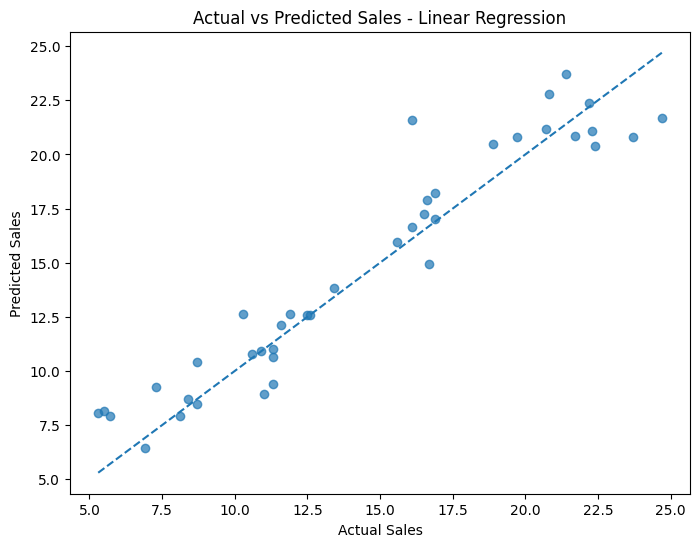

In [11]:

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    lr_predictions,
    alpha=0.7
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales - Linear Regression")
plt.show()


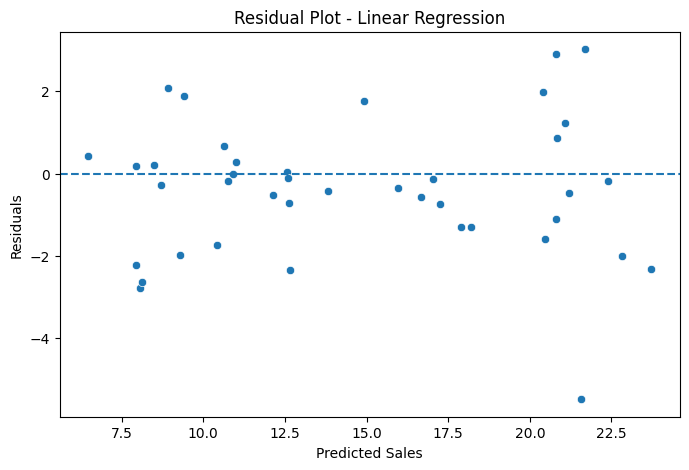

In [12]:

residuals = y_test - lr_predictions

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=lr_predictions,
    y=residuals
)

plt.axhline(y=0, linestyle='--')

plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")
plt.title("Residual Plot - Linear Regression")
plt.show()


Advertising Channel Importance:


,0
TV,0.845355
Radio,0.136642
Newspaper,0.018003


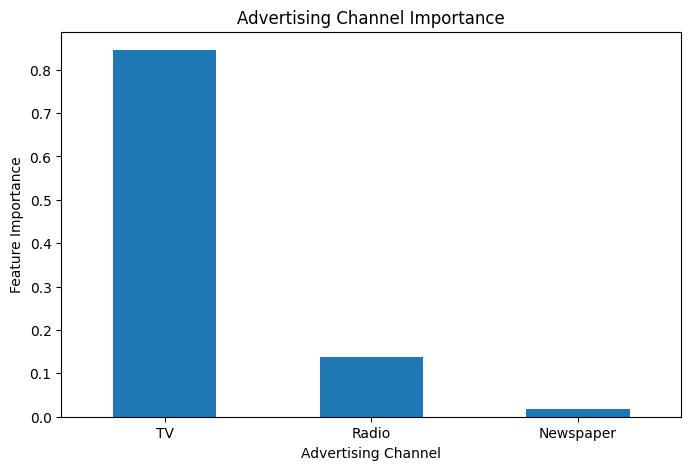

In [13]:

feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Advertising Channel Importance:")
display(feature_importance)

plt.figure(figsize=(8, 5))

feature_importance.plot(kind='bar')

plt.title("Advertising Channel Importance")
plt.xlabel("Advertising Channel")
plt.ylabel("Feature Importance")
plt.xticks(rotation=0)
plt.show()


In [14]:

X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 160
Testing samples: 40


In [15]:

lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)

print("Linear Regression Model Trained Successfully!")


Linear Regression Model Trained Successfully!


In [16]:

lr_mae = mean_absolute_error(y_test, lr_predictions)

lr_rmse = np.sqrt(
    mean_squared_error(y_test, lr_predictions)
)

lr_r2 = r2_score(y_test, lr_predictions)

print("LINEAR REGRESSION RESULTS")
print("-" * 40)
print("MAE:", round(lr_mae, 3))
print("RMSE:", round(lr_rmse, 3))
print("R2 Score:", round(lr_r2, 3))


LINEAR REGRESSION RESULTS
----------------------------------------
MAE: 1.275
RMSE: 1.705
R2 Score: 0.906


In [17]:

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest Model Trained Successfully!")


Random Forest Model Trained Successfully!


In [18]:

rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_r2 = r2_score(y_test, rf_predictions)

print("RANDOM FOREST RESULTS")
print("-" * 40)
print("MAE:", round(rf_mae, 3))
print("RMSE:", round(rf_rmse, 3))
print("R2 Score:", round(rf_r2, 3))


RANDOM FOREST RESULTS
----------------------------------------
MAE: 0.918
RMSE: 1.199
R2 Score: 0.953


In [19]:

model_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [lr_mae, rf_mae],
    'RMSE': [lr_rmse, rf_rmse],
    'R2 Score': [lr_r2, rf_r2]
})

display(model_comparison)


,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.274826,1.705215,0.905901
1,Random Forest,0.918000,1.198930,0.953483


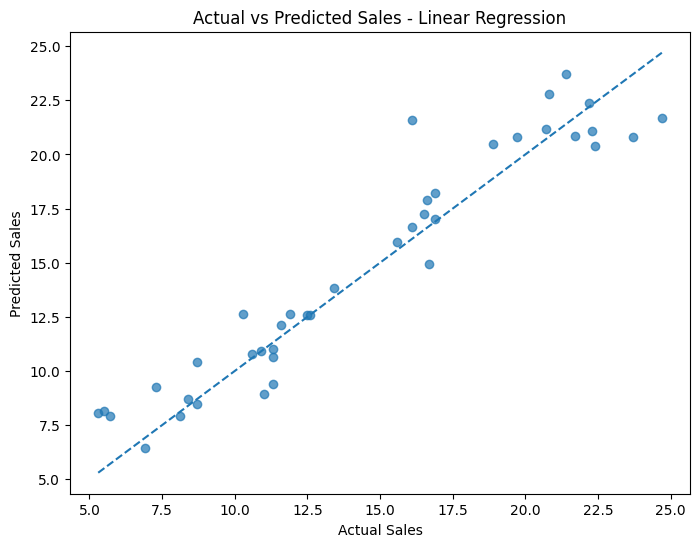

In [20]:

plt.figure(figsize=(8, 6))

plt.scatter(y_test, lr_predictions, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales - Linear Regression")
plt.show()


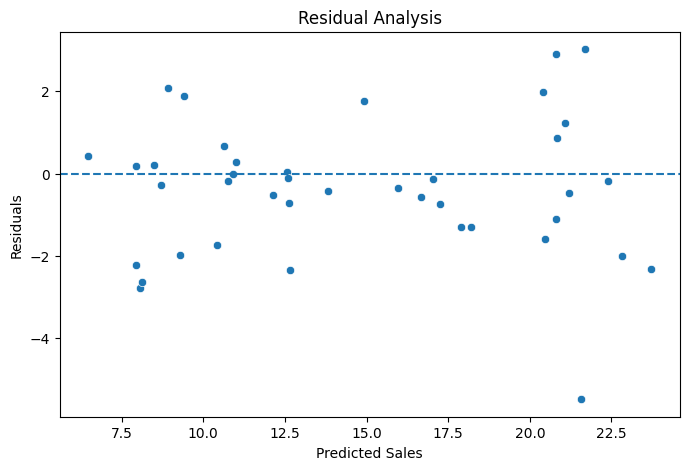

In [21]:

residuals = y_test - lr_predictions

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=lr_predictions,
    y=residuals
)

plt.axhline(y=0, linestyle='--')

plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")
plt.title("Residual Analysis")
plt.show()


,0
TV,0.845355
Radio,0.136642
Newspaper,0.018003


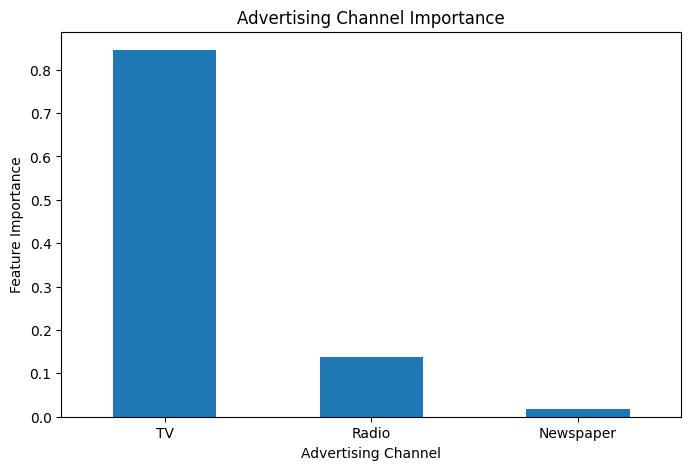

In [22]:

feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

display(feature_importance)

plt.figure(figsize=(8, 5))

feature_importance.plot(kind='bar')

plt.title("Advertising Channel Importance")
plt.xlabel("Advertising Channel")
plt.ylabel("Feature Importance")
plt.xticks(rotation=0)
plt.show()


In [23]:

print("=" * 60)
print("       SALES PREDICTION FINAL REPORT")
print("=" * 60)

print("\n1. DATASET OVERVIEW")
print("-" * 40)

print("Total Records:", len(df))
print("Total Features:", len(X.columns))
print("Missing Values:", df.isnull().sum().sum())

print("\n2. LINEAR REGRESSION PERFORMANCE")
print("-" * 40)

print("MAE:", round(lr_mae, 3))
print("RMSE:", round(lr_rmse, 3))
print("R2 Score:", round(lr_r2, 3))

print("\n3. RANDOM FOREST PERFORMANCE")
print("-" * 40)

print("MAE:", round(rf_mae, 3))
print("RMSE:", round(rf_rmse, 3))
print("R2 Score:", round(rf_r2, 3))

print("\n4. MODEL COMPARISON")
print("-" * 40)

best_model = (
    "Linear Regression"
    if lr_rmse < rf_rmse
    else "Random Forest"
)

print("Best Model based on RMSE:", best_model)

print("\n5. ADVERTISING CHANNEL IMPORTANCE")
print("-" * 40)

print(feature_importance)

print("\n6. CONCLUSION")
print("-" * 40)

print(
    f"The model with the lowest RMSE is {best_model}. "
    "The evaluation metrics help assess how accurately "
    "the model predicts sales."
)

print("\n" + "=" * 60)
print("             END OF REPORT")
print("=" * 60)



       SALES PREDICTION FINAL REPORT

1. DATASET OVERVIEW
----------------------------------------
Total Records: 200
Total Features: 3
Missing Values: 0

2. LINEAR REGRESSION PERFORMANCE
----------------------------------------
MAE: 1.275
RMSE: 1.705
R2 Score: 0.906

3. RANDOM FOREST PERFORMANCE
----------------------------------------
MAE: 0.918
RMSE: 1.199
R2 Score: 0.953

4. MODEL COMPARISON
----------------------------------------
Best Model based on RMSE: Random Forest

5. ADVERTISING CHANNEL IMPORTANCE
----------------------------------------
TV           0.845355
Radio        0.136642
Newspaper    0.018003
dtype: float64

6. CONCLUSION
----------------------------------------
The model with the lowest RMSE is Random Forest. The evaluation metrics help assess how accurately the model predicts sales.

             END OF REPORT
